# Kaggle Challenge: House Prices – mejorando la marca de clase

**Objetivo:** superar la puntuación obtenida en clase (**0.18878**) en la competición [House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques).

Kaggle evalúa con el **RMSE entre el logaritmo del precio predicho y el logaritmo del precio real** (cuanto más baja, mejor). Partimos del notebook de clase y aplicamos estas mejoras:

1. **Predecir `log(SalePrice)`** en lugar del precio directo, para optimizar exactamente lo que mide Kaggle.
2. **Eliminar outliers** conocidos (casas enormes vendidas muy baratas).
3. **Usar todas las variables** del dataset (no solo 10), con imputación de nulos y *one-hot encoding*.
4. **Crear variables nuevas** (superficie total, baños totales, antigüedad…).
5. **Cambiar de modelo**: de `LinearRegression` a `GradientBoostingRegressor`, y compararlos en validación.

## 1. Cargar los datos

Los CSV descargados de Kaggle van en la carpeta `data/` (que **no** se sube a GitHub).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns

TRAIN_CSV = 'data/train.csv'
TEST_CSV = 'data/test.csv'
SEED = 42

train_df = pd.read_csv(TRAIN_CSV)
test_df = pd.read_csv(TEST_CSV)
train_df.shape, test_df.shape

((1460, 81), (1459, 80))

## 2. EDA: variable objetivo y outliers

El precio tiene una distribución sesgada a la derecha. Al aplicar el logaritmo queda mucho más cercana a una normal, que es lo que mejor funciona para los modelos de regresión y, además, es la escala en la que puntúa Kaggle.

Text(0.5, 1.0, 'Distribución de log(SalePrice)')

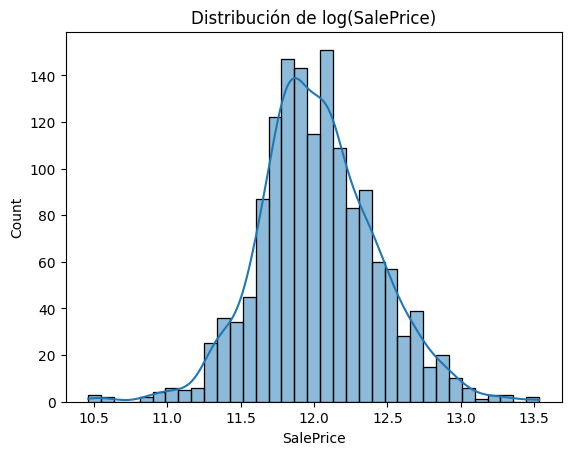

In [2]:
ax = sns.histplot(np.log1p(train_df['SalePrice']), kde=True)
ax.set_title('Distribución de log(SalePrice)')

En el gráfico de superficie habitable frente a precio aparecen dos casas de más de 4.000 pies² con un precio anormalmente bajo. Son outliers documentados por el propio autor del dataset, así que los eliminamos del entrenamiento.

Text(0.5, 1.0, 'GrLivArea vs SalePrice')

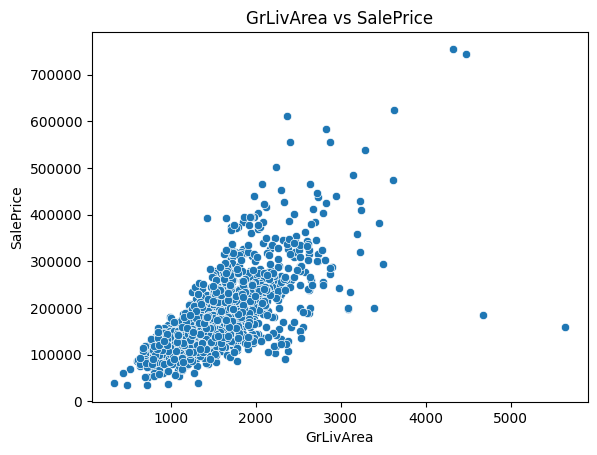

In [3]:
ax = sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice')
ax.set_title('GrLivArea vs SalePrice')

In [4]:
outliers = (train_df['GrLivArea'] > 4000) & (train_df['SalePrice'] < 300000)
print(f'Outliers eliminados: {outliers.sum()}')
train_df = train_df[~outliers].reset_index(drop=True)

Outliers eliminados: 2


## 3. Preprocesamiento

Igual que en clase, unimos train y test para aplicar las mismas transformaciones a ambos.

In [5]:
y = np.log1p(train_df['SalePrice'])  # variable objetivo en escala logarítmica
test_ids = test_df['Id']

all_data_df = pd.concat(
    [train_df.drop(columns=['SalePrice']), test_df],
    keys=['train', 'test'],
).drop(columns=['Id'])
all_data_df.shape

(2917, 79)

### 3.1 Tratar los datos nulos

En este dataset, muchos nulos categóricos significan **"no tiene"** (sin piscina, sin garaje, sin sótano…), así que los rellenamos con `'None'`. Los numéricos los rellenamos con la mediana.

In [6]:
nulls = all_data_df.isnull().sum()
nulls[nulls > 0].sort_values(ascending=False)

,0
PoolQC,2908
MiscFeature,2812
Alley,2719
Fence,2346
MasVnrType,1766
FireplaceQu,1420
LotFrontage,486
GarageQual,159
GarageYrBlt,159
GarageCond,159


In [7]:
categorical_columns = all_data_df.select_dtypes(exclude='number').columns
numeric_columns = all_data_df.select_dtypes(include='number').columns

all_data_df[categorical_columns] = all_data_df[categorical_columns].fillna('None')
all_data_df[numeric_columns] = all_data_df[numeric_columns].fillna(
    all_data_df[numeric_columns].median()
)

all_data_df.isnull().sum().sum()

np.int64(0)

### 3.2 Nuevas variables (feature engineering)

In [8]:
all_data_df['TotalSF'] = (
    all_data_df['TotalBsmtSF'] + all_data_df['1stFlrSF'] + all_data_df['2ndFlrSF']
)
all_data_df['TotalBath'] = (
    all_data_df['FullBath'] + 0.5 * all_data_df['HalfBath']
    + all_data_df['BsmtFullBath'] + 0.5 * all_data_df['BsmtHalfBath']
)
all_data_df['HouseAge'] = all_data_df['YrSold'] - all_data_df['YearBuilt']
all_data_df['RemodAge'] = all_data_df['YrSold'] - all_data_df['YearRemodAdd']
all_data_df['TotalPorchSF'] = (
    all_data_df['OpenPorchSF'] + all_data_df['EnclosedPorch']
    + all_data_df['3SsnPorch'] + all_data_df['ScreenPorch'] + all_data_df['WoodDeckSF']
)

# MSSubClass es un código de tipo de vivienda, no una cantidad: lo tratamos como categoría
all_data_df['MSSubClass'] = all_data_df['MSSubClass'].astype(str)

### 3.3 Codificar las variables categóricas

En clase usamos `LabelEncoder`, que asigna números arbitrarios a cada categoría (el modelo puede interpretar que un barrio "5" es mayor que un barrio "2"). Aquí usamos **one-hot encoding** con `pd.get_dummies`, que crea una columna binaria por categoría.

In [9]:
X_all = pd.get_dummies(all_data_df, dtype=float)
X_all.shape

(2917, 329)

## 4. Split de los datos

In [10]:
from sklearn.model_selection import train_test_split

X_test = X_all.xs('test')
X_train_full = X_all.xs('train')

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y, test_size=0.2, random_state=SEED
)

## 5. Entrenar y comparar modelos

Comparamos en validación, con la misma métrica que Kaggle (RMSE sobre el logaritmo), una regresión lineal regularizada (`Ridge`, con escalado) y un `GradientBoostingRegressor`.

In [11]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=300)),
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        max_features='sqrt',
        random_state=SEED,
    ),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    results[name] = root_mean_squared_error(y_val, y_pred)

pd.Series(results, name='RMSE (log)').sort_values()

,RMSE (log)
GradientBoosting,0.114365
Ridge,0.127830


## 6. Entrenar el modelo final

Nos quedamos con el Gradient Boosting y lo reentrenamos con **todos** los datos de entrenamiento (train + validación) para aprovechar al máximo la información antes de predecir.

In [12]:
final_model = models['GradientBoosting']
final_model.fit(X_train_full, y)

GradientBoostingRegressor(learning_rate=0.03, max_depth=4, max_features='sqrt',
                          n_estimators=1000, random_state=42, subsample=0.8)

## 7. Envío a Kaggle

El modelo predice en escala logarítmica, así que deshacemos la transformación con `np.expm1` antes de guardar.

In [13]:
test_predictions = np.expm1(final_model.predict(X_test))

submission_df = pd.DataFrame({
    'Id': test_ids,
    'SalePrice': test_predictions,
})
submission_df.to_csv('data/submission.csv', index=False)
submission_df.head()

,Id,SalePrice
0,1461,125929.828904
1,1462,159094.417039
2,1463,191154.978903
3,1464,200830.588292
4,1465,183724.339931


## 8. Resultado

| Modelo | Puntuación Kaggle |
|---|---|
| Clase: `LinearRegression`, 10 variables, precio sin log | 0.18878 |
| Este notebook: `GradientBoostingRegressor`, todas las variables, log(precio) | 0.12610|